<a href="https://colab.research.google.com/github/inosven/Neural-Networks-Zero-to-Hero/blob/main/makemore_bigram_excercise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')
with open('/content/drive/MyDrive/Colab Notebooks/Zero2Hero_Karpathy/Data/names.txt','r') as f:
  words = f.read().splitlines()

Mounted at /content/drive


In [2]:
words[:3]

['emma', 'olivia', 'ava']

In [9]:
chars = sorted(list(set(''.join(words))))

stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.']=0
itos = {i:s for s,i in stoi.items()}
print(itos)


{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [11]:
import torch

In [28]:
X, Y = [], []
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1,ch2,ch3 in zip(chs,chs[1:],chs[2:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    ix3=stoi[ch3]
    # print(ix1,ix2,ix3)
    X.append([ix1,ix2])
    Y.append(ix3)
X = torch.tensor(X)
Y = torch.tensor(Y)

In [29]:
X.shape, Y.shape

(torch.Size([196113, 2]), torch.Size([196113]))

In [15]:
import torch.nn.functional as F

In [32]:
xenc = F.one_hot(X,num_classes=27).float()
xenc.shape

torch.Size([196113, 2, 27])

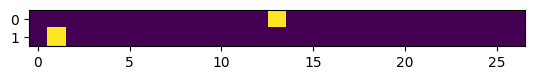

In [20]:
from matplotlib import pyplot as plt
plt.imshow(xenc[0])

In [33]:
g = torch.Generator().manual_seed(22123123)

In [34]:
W = torch.randn((27*2,27),generator=g, requires_grad=True)
logits = xenc.view(-1,27*2) @ W

In [36]:
for _ in range(100):
  #foward
  logits = xenc.view(-1,27*2) @ W
  counts = logits.exp()
  probs = counts / counts.sum(1, keepdim=True)
  loss=-probs[torch.arange(Y.shape[0]),Y].log().mean() + 0.01 * (W**2).mean()
  print(loss.item())
  #backward
  W.grad=None
  loss.backward()

  #update
  W.data += -50*W.grad

2.274409770965576
2.2741217613220215
2.2738404273986816
2.2735648155212402
2.2732951641082764
2.2730305194854736
2.2727718353271484
2.2725179195404053
2.2722690105438232
2.2720248699188232
2.271785259246826
2.2715508937835693
2.2713205814361572
2.27109432220459
2.2708725929260254
2.2706551551818848
2.2704415321350098
2.2702317237854004
2.2700252532958984
2.2698235511779785
2.2696244716644287
2.2694292068481445
2.2692372798919678
2.2690486907958984
2.2688636779785156
2.268681287765503
2.2685022354125977
2.2683262825012207
2.268153429031372
2.2679834365844727
2.2678158283233643
2.267651081085205
2.267488956451416
2.267329692840576
2.2671730518341064
2.2670185565948486
2.26686692237854
2.2667171955108643
2.2665703296661377
2.266425371170044
2.2662830352783203
2.2661421298980713
2.2660038471221924
2.2658677101135254
2.265733480453491
2.265601634979248
2.2654712200164795
2.265343427658081
2.26521635055542
2.265092134475708
2.2649688720703125
2.264848232269287
2.2647287845611572
2.2646112442

In [38]:
  xenc = F.one_hot(torch.tensor([ix1,ix2]),num_classes=27).float()
  xenc.shape
  logits = xenc.view(-1,27*2)

torch.Size([2, 27])

In [39]:
W.shape

torch.Size([54, 27])

In [41]:
for _ in range(5):
  ix1,ix2= 0,0
  out=[]
  while True:
    xenc = F.one_hot(torch.tensor([ix1,ix2]),num_classes=27).float()
    logits = xenc.view(-1,27*2) @ W
    counts = logits.exp()
    probs = counts / counts.sum(1,keepdim=True)

    ix = torch.multinomial(probs,num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    ix1,ix2 = ix2, ix
    if ix==0:
      break
  print(''.join(out))

yana.
rieal.
raha.
ulinnae.
ulann.
